# Task 1 - Smart Buildings: Dataset Understanding and Probability

**Member 1 - Data Lead**

> Member 5: replace this starter with the final problem statement, objectives, and roadmap before submission.

This notebook analyzes the Smart Buildings generator dataset. It documents the source files, defines a reproducible analysis frame, checks data quality, and publishes shared event columns for the probability applications. Later sections are reserved for the team. Results describe this generator's accepted outputs, not real-world buildings.

## 1. Setup (Member 1)

Load the three source CSVs without editing them. The notebook first checks its current folder and the usual shared Drive folder. If the files are not there and this is Colab, it asks you to upload the three CSVs. If running locally, keep this notebook beside the CSVs or set `DATA_DIR` to their folder.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

REQUIRED_FILES = ['buildings_200_features.csv', 'rejected_seeds.csv', 'feature_catalog.csv']
candidate_dirs = [Path.cwd(), Path('/content/drive/MyDrive/stats_project')]
DATA_DIR = next((p for p in candidate_dirs if all((p / f).exists() for f in REQUIRED_FILES)), None)

if DATA_DIR is None:
    try:
        from google.colab import files
        print('Upload buildings_200_features.csv, rejected_seeds.csv, and feature_catalog.csv')
        files.upload()
        DATA_DIR = Path.cwd()
    except ImportError:
        raise FileNotFoundError(
            'Could not find the three CSV files. Put them beside this notebook or change DATA_DIR to their folder.'
        )

missing_files = [f for f in REQUIRED_FILES if not (DATA_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(f'Missing {missing_files} in {DATA_DIR}. Upload all three project CSV files.')

df_raw = pd.read_csv(DATA_DIR / 'buildings_200_features.csv')
rej_raw = pd.read_csv(DATA_DIR / 'rejected_seeds.csv')
cat_raw = pd.read_csv(DATA_DIR / 'feature_catalog.csv')

print('Data folder:', DATA_DIR)
print('buildings:', df_raw.shape)
print('rejected seeds:', rej_raw.shape)
print('feature catalog:', cat_raw.shape)
assert df_raw.shape == (200, 54)
assert rej_raw.shape == (82, 2)
assert cat_raw.shape == (133, 4)

Data folder: /home/claude/work
buildings: (200, 54)
rejected seeds: (82, 2)
feature catalog: (133, 4)


## 2. Understand the files and variables (Member 1)

Each building row is one accepted generated building configuration. Its seed is the link key. The rejected-seed file records generator attempts that failed the minimum zone-area rule. Together, the 200 accepted and 82 rejected seeds make the complete contiguous run from 100000 through 100281. The feature catalog documents all 54 CSV columns and 79 additional observation features available only during simulation.

| File | Shape | One row means | Link key / use |
|---|---:|---|---|
| `buildings_200_features.csv` | 200 x 54 | One accepted generated building | `cfg__seed` (also recorded as `meta__seed_requested`) |
| `rejected_seeds.csv` | 82 x 2 | One refused generator seed and its reason | `seed` |
| `feature_catalog.csv` | 133 x 4 | One feature definition | `column`; 54 are in the CSV and 79 are simulation-only |

Groups: `meta` records provenance, `cfg` records static configuration, `derived` records structure measured from generated files, and `obs` records observation-schema counts/derived vector length. The observation values themselves are not stored per building in this CSV.

In [2]:
# A small readable sample: selected columns cover identifiers, configuration, structure, and schema.
sample_cols = [
    'meta__seed_requested', 'cfg__name', 'cfg__floor_plan.building_shape',
    'cfg__floor_plan.num_floors', 'cfg__ahu.num_ahus', 'derived__n_zones',
    'derived__ahus_added_beyond_config', 'cfg__simulation.occupants_per_zone',
    'obs__expected_vector_length_derived'
]
df_raw.sample(5, random_state=42)[sample_cols]

,meta__seed_requested,cfg__name,cfg__floor_plan.building_shape,cfg__floor_plan.num_floors,cfg__ahu.num_ahus,derived__n_zones,derived__ahus_added_beyond_config,cfg__simulation.occupants_per_zone,obs__expected_vector_length_derived
95,100142,building_100142,composite,2,7,35,0,2,373
15,100019,building_100019,composite,3,4,47,1,1,415
30,100041,building_100041,composite,2,6,57,0,2,490
158,100225,building_100225,composite,2,5,52,1,1,460
128,100186,building_100186,composite,4,7,138,7,1,1096


### Variable dictionary

The next table includes every CSV field. `Meaning` is a plain-English guide inferred from the feature name and the catalog's group/kind; the catalog remains the authoritative source for the feature definition.

In [3]:
def classify_type(column, series):
    name = column.split('__', 1)[-1]
    if 'timestamp' in name or 'date' in name or 'time' in name:
        return 'date/time'
    if pd.api.types.is_numeric_dtype(series):
        if pd.api.types.is_integer_dtype(series):
            return 'numeric-discrete'
        return 'numeric-continuous'
    if any(token in name for token in ('name', 'sha256', 'output_files', 'shape')):
        return 'text/identifier'
    return 'categorical'

def plain_meaning(column):
    n = column.split('__', 1)[-1]
    meanings = {
        'seed_requested':'Seed requested by the generator', 'seed':'Seed saved in the building configuration',
        'weather_preset':'Weather preset used for scenario generation', 'generator_output_files':'Generated file names',
        'arrays_sha256':'Hash used to identify generated array contents', 'name':'Generated building name',
        'ahu.num_ahus':'Configured number of air handlers', 'ahu.max_zones_per_ahu':'Maximum zones per air handler',
        'floor_plan.building_shape':'Footprint shape family', 'floor_plan.composite_coverage':'Share of footprint covered by composite geometry',
        'floor_plan.composite_style':'Composite footprint style', 'floor_plan.height':'Building height parameter',
        'floor_plan.max_room_size':'Configured maximum room size', 'floor_plan.min_room_size':'Configured minimum room size',
        'floor_plan.num_floors':'Configured number of floors', 'floor_plan.shape_ratio':'Footprint width-to-height shape parameter',
        'floor_plan.width':'Footprint width parameter', 'materials.exterior_cv_conductivity':'Exterior construction conductivity parameter',
        'materials.exterior_cv_density':'Exterior construction density parameter', 'materials.exterior_cv_heat_capacity':'Exterior construction heat-capacity parameter',
        'materials.interior_mass_cv_density':'Interior mass density parameter', 'materials.interior_wall_cv_conductivity':'Interior wall conductivity parameter',
        'materials.interior_wall_cv_density':'Interior wall density parameter', 'simulation.num_days_in_episode':'Simulation episode length in days',
        'simulation.occupants_per_zone':'Configured occupants per zone', 'simulation.start_timestamp':'Simulation start time',
        'n_zones':'Number of generated thermal zones', 'n_vav_boxes':'Number of VAV boxes', 'n_ahus':'Number of air handlers in generated scenario',
        'ahus_configured':'Configured AHU count', 'ahus_added_beyond_config':'AHUs added beyond configured count',
        'max_zones_per_ahu':'Maximum zones assigned to an AHU', 'num_floors':'Floor count measured from generated structure',
        'max_rooms_on_one_ahu':'Maximum rooms assigned to one AHU', 'min_rooms_on_one_ahu':'Minimum rooms assigned to one AHU',
        'n_hot_water_systems':'Number of hot-water systems', 'min_ahus_required':'Minimum AHUs required by the generated structure',
        'floor_plan_shape':'Shape of the floor-plan array', 'zone_map_shape':'Shape of the zone-map array',
        'zone_cells_min':'Minimum grid cells in a zone', 'zone_cells_mean':'Mean grid cells per zone', 'zone_cells_max':'Maximum grid cells in a zone',
        'n_zone_feature_types':'Number of observation feature types per zone', 'expected_zone_elements':'Derived total zone observation elements',
        'n_ahu_feature_types':'Number of observation feature types per AHU', 'expected_ahu_elements':'Derived total AHU observation elements',
        'n_hot_water_feature_types':'Number of hot-water observation feature types', 'expected_hot_water_elements':'Derived hot-water observation elements',
        'n_time_feature_types':'Number of time-indexed observation feature types', 'expected_time_elements':'Derived time-indexed observation elements',
        'n_building_feature_types':'Number of building-wide observation feature types', 'expected_building_elements':'Derived building-wide observation elements',
        'n_feature_types_total':'Total observation feature types', 'expected_vector_length_derived':'Derived total observation vector length'
    }
    return meanings.get(n, f'{n.replace(".", " ").replace("_", " ").capitalize()} (see feature catalog)')

catalog_csv = cat_raw.loc[cat_raw['in_csv'].astype(bool)].set_index('column')
variable_dictionary = pd.DataFrame([
    {'column': c, 'group': catalog_csv.loc[c, 'group'], 'meaning': plain_meaning(c),
     'type': classify_type(c, df_raw[c]), 'catalog_kind': catalog_csv.loc[c, 'kind']}
    for c in df_raw.columns
])
assert len(variable_dictionary) == 54
variable_dictionary

,column,group,meaning,type,catalog_kind
0,meta__seed_requested,meta,Seed requested by the generator,numeric-discrete,metadata / provenance
1,meta__weather_preset,meta,Weather preset used for scenario generation,categorical,metadata / provenance
2,meta__generator_output_files,meta,Generated file names,text/identifier,metadata / provenance
3,cfg__ahu.num_ahus,cfg,Configured number of air handlers,numeric-discrete,static building configuration (from generated ...
4,cfg__floor_plan.building_shape,cfg,Footprint shape family,text/identifier,static building configuration (from generated ...
5,cfg__floor_plan.composite_coverage,cfg,Share of footprint covered by composite geometry,numeric-continuous,static building configuration (from generated ...
6,cfg__floor_plan.composite_style,cfg,Composite footprint style,categorical,static building configuration (from generated ...
7,cfg__floor_plan.height,cfg,Building height parameter,numeric-discrete,static building configuration (from generated ...
8,cfg__floor_plan.max_room_size,cfg,Configured maximum room size,numeric-discrete,static building configuration (from generated ...
9,cfg__floor_plan.min_room_size,cfg,Configured minimum room size,numeric-discrete,static building configuration (from generated ...


## 3. Minimal preprocessing and quality checks (Member 1)

The source data is already clean: we expect no missing values and no duplicate building rows, so no observations need to be fixed or removed. Keep `df_raw`, `rej_raw`, and `cat_raw` unchanged. In the analysis copy, shorten field names by removing only the first group prefix, then omit constant columns because they cannot define a non-trivial event in this sample. Keep valid outliers, including buildings with up to 305 zones. All probability results on `df` therefore describe accepted buildings and are conditional on the generator accepting them.

In [4]:
preprocess_log = []
def log_step(name, frame):
    preprocess_log.append({'step': name, 'rows': len(frame), 'columns': frame.shape[1]})
    print(f"{name}: {len(frame)} rows x {frame.shape[1]} columns")

log_step('Raw building file', df_raw)
df = df_raw.copy()
df.columns = [c.split('__', 1)[1] for c in df.columns]
log_step('Shortened group-prefixed names', df)
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=const_cols)
log_step(f'Dropped {len(const_cols)} constant columns (analysis frame only)', df)

# Quality checks required for the shared data contract.
missing_total = int(df_raw.isna().sum().sum())
duplicate_rows = int(df_raw.duplicated().sum())
assert missing_total == 0
assert duplicate_rows == 0
assert df.seed.is_unique
assert df.arrays_sha256.is_unique
assert (df.n_zones == df.n_vav_boxes).all()
assert (df.n_ahus == df['ahu.num_ahus'] + df.ahus_added_beyond_config).all()

accepted_seeds = set(df.seed.astype(int))
rejected_seed_set = set(rej_raw.seed.astype(int))
expected_seeds = set(range(100000, 100282))
assert accepted_seeds.isdisjoint(rejected_seed_set)
assert accepted_seeds | rejected_seed_set == expected_seeds
assert len(accepted_seeds) == 200 and len(rejected_seed_set) == 82

quality_checks = pd.Series({
    'missing cells in raw buildings': missing_total,
    'duplicate raw rows': duplicate_rows,
    'building seeds unique': df.seed.is_unique,
    'array hashes unique': df.arrays_sha256.is_unique,
    'n_zones equals n_vav_boxes for every row': (df.n_zones == df.n_vav_boxes).all(),
    'n_ahus equals configured plus added for every row': (df.n_ahus == df['ahu.num_ahus'] + df.ahus_added_beyond_config).all(),
    'accepted/rejected seeds disjoint and complete': accepted_seeds.isdisjoint(rejected_seed_set) and accepted_seeds | rejected_seed_set == expected_seeds
}, name='result')
display(quality_checks.to_frame())
display(pd.DataFrame(preprocess_log))
print('Constant columns (kept in df_raw):', const_cols)

Raw building file: 200 rows x 54 columns
Shortened group-prefixed names: 200 rows x 54 columns
Dropped 17 constant columns (analysis frame only): 200 rows x 37 columns


,result
missing cells in raw buildings,0
duplicate raw rows,0
building seeds unique,True
array hashes unique,True
n_zones equals n_vav_boxes for every row,True
n_ahus equals configured plus added for every row,True
accepted/rejected seeds disjoint and complete,True


,step,rows,columns
0,Raw building file,200,54
1,Shortened group-prefixed names,200,54
2,Dropped 17 constant columns (analysis frame only),200,37


Constant columns (kept in df_raw): ['weather_preset', 'floor_plan.building_shape', 'floor_plan.composite_style', 'simulation.num_days_in_episode', 'simulation.start_timestamp', 'max_zones_per_ahu', 'n_hot_water_systems', 'n_zone_feature_types', 'n_ahu_feature_types', 'n_hot_water_feature_types', 'expected_hot_water_elements', 'n_time_feature_types', 'expected_time_elements', 'n_building_feature_types', 'expected_building_elements', 'n_feature_types_total', 'ahu.max_zones_per_ahu']


## 4. Rejected seeds and shared event columns (Member 1)

Parse the rejection reason into the number of undersized zones and the smallest zone area. Build one row per attempted seed with an `accepted` flag. Publish the following reusable Boolean columns without renaming: `A_large`, `B_extra_ahu`, `F2`, `F3`, `F4`, and `O2`. The large-building threshold is the median zone count (64) and uses a strict greater-than comparison, so ties remain in the not-large group.

In [5]:
rej = rej_raw.copy()
rej['n_small_zones'] = rej.reason.str.extract(r'produces (\d+) zone')[0].astype(int)
rej['smallest_m2'] = rej.reason.str.extract(r'smallest ([\d.]+) m2')[0].astype(float)
assert rej[['n_small_zones', 'smallest_m2']].notna().all().all()

seeds = pd.DataFrame({'seed': range(100000, 100282)})
seeds['accepted'] = seeds.seed.isin(accepted_seeds)
assert seeds.accepted.sum() == 200 and (~seeds.accepted).sum() == 82

zone_median = df.n_zones.median()
df['A_large'] = df.n_zones > zone_median
df['B_extra_ahu'] = df.ahus_added_beyond_config > 0
df['F2'] = df['floor_plan.num_floors'] == 2
df['F3'] = df['floor_plan.num_floors'] == 3
df['F4'] = df['floor_plan.num_floors'] == 4
df['O2'] = df['simulation.occupants_per_zone'] == 2

event_counts = pd.Series({
    'A_large (n_zones > median)': int(df.A_large.sum()),
    'B_extra_ahu': int(df.B_extra_ahu.sum()),
    'F2': int(df.F2.sum()), 'F3': int(df.F3.sum()), 'F4': int(df.F4.sum()),
    'O2': int(df.O2.sum()),
}, name='count')
display(event_counts.to_frame())
print('Shared event columns:', ['A_large', 'B_extra_ahu', 'F2', 'F3', 'F4', 'O2'])

,count
A_large (n_zones > median),98
B_extra_ahu,146
F2,74
F3,63
F4,63
O2,108


Shared event columns: ['A_large', 'B_extra_ahu', 'F2', 'F3', 'F4', 'O2']


### Preprocessing notes and limitations (Member 1)

No building rows were removed: the analysis retains all 200 accepted configurations. Constant columns were removed only from `df`, not from the source or `df_raw`; dropping them does not change any event probability. Redundant measures such as zone count and VAV-box count remain available for interpretation but carry the same information in this dataset. The 82 rejected seeds are tracked separately and are not mixed into building-level probability denominators.

The buildings are generator outputs, not a random sample of real buildings. Conclusions are conditional on generator acceptance and this seed range. There is no energy-use or comfort outcome in these files. Observation vector lengths are derived from a schema formula rather than measured for every building in a live rollout. All buildings use the same weather preset, and the sample contains constants and redundant features. The median threshold is a convenient convention, not a physical definition of complexity.

## 5. Probability applications (Members 2-4)

Team members: add each application using the required five-part template: question; events and assumptions; rule and why it fits; calculation and result; interpretation. Keep this section after the shared event-column cell.

### 5.0 Member 2 setup: Probability A (foundations and counting)

Applications 1-5 below cover sample spaces and events, the axioms, the complement rule, counting techniques, the addition rule, and a second probability model on the rejected seeds. Each application follows the same five parts: **question; events and assumptions; rule and why it fits; calculation and result; interpretation**.

This cell checks that Member 1's shared columns exist before we build on them, fixes the random seed (42), and creates `m2_results`, the dictionary of rule-based values handed to Member 4 for validation.

In [6]:
from math import comb, perm
from itertools import combinations
import json, os
import matplotlib.pyplot as plt

RANDOM_SEED = 42                      # fixed seed: reruns give identical numbers
rng = np.random.default_rng(RANDOM_SEED)
PALETTE = {'main': '#2F5D8C', 'accent': '#D9822B', 'grey': '#8A8F98'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 12, 'axes.labelsize': 10})
os.makedirs('figures', exist_ok=True)

# Confirm Member 1's data contract is intact (names must not change).
events = ['A_large', 'B_extra_ahu', 'F2', 'F3', 'F4', 'O2']
for col in events:
    assert col in df.columns and df[col].dtype == bool, f'Problem with event column {col}'
print(df[events].sum().to_string())
print('seeds table:', seeds.shape, '| accepted:', int(seeds.accepted.sum()), '| rejected:', int((~seeds.accepted).sum()))
print('rejected-seed table:', rej.shape)

m2_results = {}                       # rule-based results handed to Member 4

A_large         98
B_extra_ahu    146
F2              74
F3              63
F4              63
O2             108
seeds table: (282, 2) | accepted: 200 | rejected: 82
rejected-seed table: (82, 4)


## 5.1 Sample space, events, axioms and the complement rule (Member 2)

### Application 1 - Sample space and events: how often does the generator reject a seed?

**Question.** What is the probability that a seed tried by the generator is rejected?

**Events and assumptions.** The sample space **S** is the 282 seeds 100000-100281, every seed the generator tried. Event **R** = "seed rejected" (the minimum-zone-area check failed). Assumption: the seeds are treated as equally likely draws from the generator. The generator is deterministic, so this is a modelling assumption and the probability is a relative frequency over this seed range.

**Rule and why it fits.** For equally likely outcomes in a finite sample space, P(R) = |R| / |S|. We use S = 282 and not 200: the 200 buildings are only the accepted outcomes, so using them would answer a different question.

In [7]:
S_size = len(seeds)                      # |S|
R_mask = ~seeds.accepted                 # True for rejected seeds
R_size = int(R_mask.sum())               # |R|
p_R = R_size / S_size

# Independent check: count the rejected seeds two other ways.
assert R_size == len(rej_raw) == len(set(range(100000, 100282)) - set(df.seed))

print(f'|S| = {S_size}, |R| = {R_size}')
print(f'P(R) = {R_size}/{S_size} = {p_R:.4f}')

# Practical use: seeds needed for N usable buildings = N / P(accepted)
p_acc = 1 - p_R
for N in (200, 1000):
    print(f'To get {N} usable buildings, try about {N / p_acc:.0f} seeds')
m2_results['P(R)'] = p_R

|S| = 282, |R| = 82
P(R) = 82/282 = 0.2908
To get 200 usable buildings, try about 282 seeds
To get 1000 usable buildings, try about 1410 seeds


**Result.** P(R) = 82/282 = 0.291.

**Interpretation.** About 29% of the seeds the generator tries are wasted; only about 71% give a usable building. To obtain N buildings, organizers should plan to try about N / 0.709 seeds (about 1,410 for 1,000 buildings). The rate belongs to this seed range and is not a universal constant of the generator. The run stopped at the 200th accepted building, so the last seed is accepted by construction; the effect on 82/282 is negligible.

### Application 2 - Axioms and the complement rule

**Question.** (a) Is the empirical distribution of `num_floors` a valid probability model? (b) What is the probability that a building needs *no* extra AHU?

**Events and assumptions.** The sample space is the 200 accepted buildings (conditional on acceptance). Outcomes are the floor counts 2, 3, 4 with F2, F3, F4 as events. B = "the scenario generator added AHUs beyond the configured number".

**Rules and why they fit.**
- *Axioms:* (1) P(E) >= 0, (2) P(S) = 1, (3) P(E1 or E2) = P(E1) + P(E2) when E1 and E2 are disjoint. A set of numbers is a valid probability model only if it satisfies all three, so we test each one.
- *Complement rule:* P(not B) = 1 - P(B). It fits because "no extra AHU" is exactly the complement of B, and it is easier to compute from P(B) than to build separately. We confirm it with two direct counts.

floor_plan.num_floors
2    0.370
3    0.315
4    0.315
Sum over S = 1.0
P(F2 or F3) = 0.685  vs  P(F2)+P(F3) = 0.685
P(B) = 0.730
P(not B): rule = 0.270 | count = 0.270 (54/200) | n_ahus==configured = 0.270


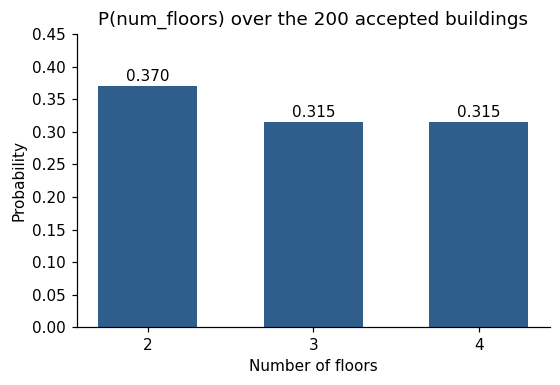

In [8]:
floors = df['floor_plan.num_floors']
p_floor = floors.value_counts(normalize=True).sort_index()
print(p_floor.round(3).to_string())

# Axiom 1: every probability is non-negative
assert (p_floor >= 0).all()
# Axiom 2: the probabilities over the whole sample space add to 1
print('Sum over S =', p_floor.sum())
assert np.isclose(p_floor.sum(), 1.0)
# Axiom 3: additivity for disjoint events (F2 and F3 cannot both happen)
assert (df.F2 & df.F3).sum() == 0
print('P(F2 or F3) =', (df.F2 | df.F3).mean(), ' vs  P(F2)+P(F3) =', p_floor[2] + p_floor[3])
assert np.isclose((df.F2 | df.F3).mean(), p_floor[2] + p_floor[3])

# Complement rule, checked three ways
p_B = df.B_extra_ahu.mean()
p_notB_rule   = 1 - p_B                                  # rule
p_notB_count  = (~df.B_extra_ahu).mean()                 # direct count of the complement
p_notB_config = (df.n_ahus == df['ahu.num_ahus']).mean() # independent: AHU count equals configured count
print(f'P(B) = {p_B:.3f}')
print(f'P(not B): rule = {p_notB_rule:.3f} | count = {p_notB_count:.3f} ({int((~df.B_extra_ahu).sum())}/200) | n_ahus==configured = {p_notB_config:.3f}')
assert np.isclose(p_notB_rule, p_notB_count) and np.isclose(p_notB_count, p_notB_config)

m2_results.update({'P(B)': p_B, 'P(not B)': p_notB_rule,
                   'P(F2)': p_floor[2], 'P(F3)': p_floor[3], 'P(F4)': p_floor[4]})

fig, ax = plt.subplots(figsize=(5.2, 3.6))
bars = ax.bar([str(k) for k in p_floor.index], p_floor.values, color=PALETTE['main'], width=0.6)
for b, v in zip(bars, p_floor.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f'{v:.3f}', ha='center', fontsize=10)
ax.set_ylim(0, 0.45); ax.set_xlabel('Number of floors'); ax.set_ylabel('Probability')
ax.set_title('P(num_floors) over the 200 accepted buildings')
plt.tight_layout(); plt.savefig('figures/fig_floors_pmf.png'); plt.show()

**Result.** P(2) = 0.370, P(3) = 0.315, P(4) = 0.315; all are non-negative, they sum to 1, and F2 and F3 are disjoint so their probabilities add. P(not B) = 1 - 0.73 = 0.27 (54 of 200), identical by the rule, by the direct count, and by checking that `n_ahus` equals the configured AHU count.

**Interpretation.** The empirical floor distribution is a valid probability model. Only about 1 building in 4 stays within its configured AHU count; the other 73% need the scenario generator to add air handlers.

## 5.2 Counting techniques (Member 2)

### Application 3 - Counting: combinations, permutations, the multiplication principle

**Question.** How many ways can we select or arrange buildings, and what does that tell us about drawing review samples, assigning train/validation/test roles and covering the configuration space?

**Events and assumptions.** Buildings are distinguishable (each has its own seed), the 200 accepted buildings are the population, and every selection is equally likely. Counting-based probability = favourable selections / all selections.

**Rules and why they fit.**
- *Combinations* C(n, k) = n! / (k!(n-k)!): order does not matter when a reviewer picks 3 buildings to inspect. P(all 3 needed extra AHUs) = C(146,3) / C(200,3), sampling **without replacement** because the same building cannot be picked twice.
- *Permutations* P(n, k) = n! / (n-k)!: order matters when the first building is for train, the second for validation, the third for test.
- *Multiplication principle:* independent choices multiply, so 3 floor options x 5 AHU options x 2 occupant options = 30 configuration cells.
- *Train/test splits:* the number of 140/60 splits is C(200, 140).

In [9]:
n = len(df); n_B = int(df.B_extra_ahu.sum())

# (a) Combinations: 3 buildings picked at random, all needed extra AHUs
p_all3 = comb(n_B, 3) / comb(n, 3)
p_approx = (n_B / n) ** 3                       # with-replacement approximation
p_seq = (n_B/n) * ((n_B-1)/(n-1)) * ((n_B-2)/(n-2))   # picking one at a time, no replacement
print(f'C({n_B},3) / C({n},3) = {comb(n_B,3)} / {comb(n,3)} = {p_all3:.4f}')
print(f'with-replacement approximation 0.73^3 = {p_approx:.4f}  (gap {p_approx - p_all3:+.4f})')
print(f'one-at-a-time product              = {p_seq:.4f}')

# Independent check: enumerate every one of the 1,313,400 triples and count directly
flags = df.B_extra_ahu.tolist()
good = sum(1 for i, j, k in combinations(range(n), 3) if flags[i] and flags[j] and flags[k])
print('Enumerated triples:', comb(n, 3), '| all-three-extra-AHU triples:', good, '| P =', round(good / comb(n, 3), 4))
assert good == comb(n_B, 3) and np.isclose(p_all3, p_seq)

# (b) Permutations vs combinations
print(f'Ordered (train, val, test) triples  P(200,3) = {perm(n,3):,}')
print(f'Unordered triples                   C(200,3) = {comb(n,3):,}')
print(f'Ratio = {perm(n,3) // comb(n,3)} = 3! (the orderings of one triple)')

# (c) Multiplication principle on the configuration space
levels = {'floors': sorted(floors.unique()),
          'num_ahus': sorted(df['ahu.num_ahus'].unique()),
          'occupants': sorted(df['simulation.occupants_per_zone'].unique())}
n_cells = int(np.prod([len(v) for v in levels.values()]))
print('Option counts:', {k: len(v) for k, v in levels.items()}, '->', n_cells, 'possible cells')
cell_counts = df.groupby(['floor_plan.num_floors', 'ahu.num_ahus', 'simulation.occupants_per_zone']).size()
full_index = pd.MultiIndex.from_product(levels.values())
cell_counts = cell_counts.reindex(full_index, fill_value=0)
print(f'Cells observed: {(cell_counts > 0).sum()} of {n_cells}; empty cells: {(cell_counts == 0).sum()}')
print(f'Buildings per cell: min {cell_counts.min()}, max {cell_counts.max()}, uniform expectation {n/n_cells:.1f}')
display(cell_counts.unstack(level=-1).rename_axis(['floors', 'num_ahus']).add_prefix('occupants='))

# (d) Train/test splits
n_splits = comb(200, 140)
assert n_splits == comb(200, 60)
print(f'Possible 140/60 splits: C(200,140) has {len(str(n_splits))} digits (about {n_splits:.2e})')

m2_results.update({'P(all 3 extra AHU, no replacement)': p_all3, 'P(all 3, with-replacement approx)': p_approx,
                   'perm(200,3)': perm(n,3), 'comb(200,3)': comb(n,3), 'config cells observed': int((cell_counts>0).sum())})

C(146,3) / C(200,3) = 508080 / 1313400 = 0.3868
with-replacement approximation 0.73^3 = 0.3890  (gap +0.0022)
one-at-a-time product              = 0.3868
Enumerated triples: 1313400 | all-three-extra-AHU triples: 508080 | P = 0.3868
Ordered (train, val, test) triples  P(200,3) = 7,880,400
Unordered triples                   C(200,3) = 1,313,400
Ratio = 6 = 3! (the orderings of one triple)
Option counts: {'floors': 3, 'num_ahus': 5, 'occupants': 2} -> 30 possible cells
Cells observed: 30 of 30; empty cells: 0
Buildings per cell: min 2, max 12, uniform expectation 6.7


occupants=1  occupants=2
floors num_ahus                          
2      3                   7            7
       4                   3           12
       5                   6           11
       6                   9            9
       7                   6            4
3      3                   4           10
       4                  10            9
       5                   4            4
       6                   5            2
       7                   5           10
4      3                   7            8
       4                   5            6
       5                   4            8
       6                   6            5
       7                  11            3

Possible 140/60 splits: C(200,140) has 52 digits (about 7.04e+51)


**Result.** P(all 3 picked buildings needed extra AHUs) = C(146,3)/C(200,3) = 0.3868. The with-replacement shortcut 0.73^3 = 0.3890 is slightly larger. Enumerating all 1,313,400 triples gives exactly the same count as the formula. There are 7,880,400 ordered (train, validation, test) triples versus 1,313,400 unordered ones (a factor of 3! = 6). All 30 configuration cells occur (2 to 12 buildings each), and there are about 10^52 possible 140/60 splits.

**Interpretation.**
- *Why the small gap:* when a building is picked, it cannot be picked again, so the proportion of "extra-AHU" buildings left drops a little with each pick. With replacement ignores that. The gap is small because 3 is tiny compared with 200.
- *Order:* use combinations when only *which* buildings matter (a review sample) and permutations when *roles* matter (train/validation/test).
- *Coverage:* the sample covers every configuration cell, but with few buildings in some cells (as few as 2), so cell-level statements are noisy.
- *Splits:* the number of possible splits is astronomically large, which is why one fixed split with a fixed seed must be reported to make results reproducible.

## 5.3 The addition rule (Member 2)

### Application 4 - Addition rule: general case and mutually exclusive case

**Question.** (a) What is the probability that a building is large **or** needs an extra AHU? (b) What is the probability that a building has 2 floors **or** 4 floors?

**Events and assumptions.** A = n_zones > 64 (the median), B = extra AHU. A and B can both happen, so they overlap. F2 and F4 describe the same variable and cannot both be true.

**Rules and why they fit.**
- *General addition rule:* P(A or B) = P(A) + P(B) - P(A and B). It fits because A and B overlap; plain addition would count the buildings in both events twice.
- *Mutually exclusive case:* P(F2 or F4) = P(F2) + P(F4), because P(F2 and F4) = 0 and there is nothing to subtract.

In [10]:
A, B = df.A_large, df.B_extra_ahu
p_A, p_B, p_AB = A.mean(), B.mean(), (A & B).mean()

p_or_rule   = p_A + p_B - p_AB                 # general addition rule
p_or_direct = (A | B).mean()                   # direct count: rows where A or B is True
print(f'P(A)={p_A:.3f}  P(B)={p_B:.3f}  P(A and B)={p_AB:.3f}')
print(f'Rule:   {p_A:.3f} + {p_B:.3f} - {p_AB:.3f} = {p_or_rule:.3f}')
print(f'Direct: {int((A | B).sum())}/200 = {p_or_direct:.3f}')
print(f'Naive sum without subtracting = {p_A + p_B:.3f}  (impossible: above 1)')
assert np.isclose(p_or_rule, p_or_direct)

# Complement cross-check: neither large nor extra AHU
print('P(neither) =', round(1 - p_or_rule, 3), '| direct count =', int((~A & ~B).sum()), 'buildings')

# Mutually exclusive case
assert (df.F2 & df.F4).sum() == 0
p_2or4_rule = df.F2.mean() + df.F4.mean()
p_2or4_direct = (df.F2 | df.F4).mean()
print(f'P(F2 or F4): rule {p_2or4_rule:.3f} | direct {p_2or4_direct:.3f} | overlap count {(df.F2 & df.F4).sum()}')
assert np.isclose(p_2or4_rule, p_2or4_direct)

m2_results.update({'P(A and B)': p_AB, 'P(A or B)': p_or_rule, 'P(F2 or F4)': p_2or4_rule})

P(A)=0.490  P(B)=0.730  P(A and B)=0.485
Rule:   0.490 + 0.730 - 0.485 = 0.735
Direct: 147/200 = 0.735
Naive sum without subtracting = 1.220  (impossible: above 1)
P(neither) = 0.265 | direct count = 53 buildings
P(F2 or F4): rule 0.685 | direct 0.685 | overlap count 0


**Result.** P(A or B) = 0.49 + 0.73 - 0.485 = 0.735 (147 of 200 buildings), matching the direct count. P(F2 or F4) = 0.37 + 0.315 = 0.685, with no overlap.

**Interpretation.** Almost every building (73.5%) is either large or needs extra AHUs, and only 53 are neither. The overlap term is large (0.485) because the two events are strongly linked: nearly all large buildings need extra AHUs (the dependence is studied in Applications 6-10). Adding 0.49 + 0.73 would give 1.22, which cannot be a probability, showing why the overlap must be subtracted. For floors the buildings fall into exactly one group, so nothing is subtracted.

## 5.4 The rejected seeds as a second probability model (Member 2)

### Application 5 - Why do seeds fail? Conditional probabilities inside R

**Question.** Given that a seed was rejected, how bad was the failure?

**Events and assumptions.** The sample space is now the 82 rejected seeds, which is the event R from Application 1. Every probability below is therefore conditional on R: P(E | R) = |E and R| / |R|. E1 = exactly 1 undersized zone; E2 = smallest zone under 5 m2; E3 = 3 or more undersized zones. (An "undersized" zone is below the generator's 20 m2 minimum.) These counts were parsed from the rejection text by Member 1.

**Rule and why it fits.** Classical probability on the restricted sample space. This is the first use of conditioning in the notebook, and it fits because the rejected-seed file contains only failures; mixing in the accepted buildings would hide the failure pattern.

,event,count,P(E | R)
0,E1: exactly 1 undersized zone,54,0.659
1,E2: smallest zone < 5 m2,26,0.317
2,E3: 3+ undersized zones,11,0.134


Distribution of n_small_zones: {1: 54, 2: 17, 3: 7, 4: 1, 5: 2, 7: 1}
mean = 1.59, max = 7
P(E1 or E3 | R) = 0.793  (disjoint, so we add)
P(E1 or E2 | R) = 0.829  (overlap 12 subtracted)
Single-zone failures: median smallest zone = 10.0 m2; 12 of 54 were within 5 m2 of the limit


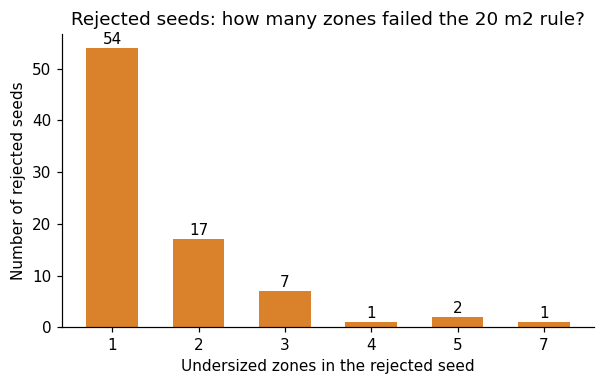

In [11]:
R_n = len(rej)
E1 = rej.n_small_zones == 1
E2 = rej.smallest_m2 < 5
E3 = rej.n_small_zones >= 3

tbl = pd.DataFrame({'event': ['E1: exactly 1 undersized zone', 'E2: smallest zone < 5 m2', 'E3: 3+ undersized zones'],
                    'count': [int(E1.sum()), int(E2.sum()), int(E3.sum())]})
tbl['P(E | R)'] = (tbl['count'] / R_n).round(3)
display(tbl)

dist = rej.n_small_zones.value_counts().sort_index()
print('Distribution of n_small_zones:', dist.to_dict())
print(f'mean = {rej.n_small_zones.mean():.2f}, max = {rej.n_small_zones.max()}')
assert np.isclose(dist.sum(), R_n) and np.isclose((dist / R_n).sum(), 1)   # valid distribution again

# E1 and E3 are disjoint, E1 and E2 overlap -> addition rule on the second model
p_E1orE3 = E1.mean() + E3.mean()
assert np.isclose(p_E1orE3, (E1 | E3).mean())
print(f'P(E1 or E3 | R) = {p_E1orE3:.3f}  (disjoint, so we add)')
print(f'P(E1 or E2 | R) = {E1.mean() + E2.mean() - (E1 & E2).mean():.3f}  (overlap {(E1 & E2).sum()} subtracted)')

# How close were the failures to the 20 m2 limit?
single = rej[E1]
print(f'Single-zone failures: median smallest zone = {single.smallest_m2.median():.1f} m2; '
      f'{int((single.smallest_m2 >= 15).sum())} of {len(single)} were within 5 m2 of the limit')

m2_results.update({'P(E1|R)': E1.mean(), 'P(E2|R)': E2.mean(), 'P(E3|R)': E3.mean(),
                   'mean n_small_zones': rej.n_small_zones.mean()})

fig, ax = plt.subplots(figsize=(5.6, 3.6))
bars = ax.bar(dist.index.astype(str), dist.values, color=PALETTE['accent'], width=0.6)
for b, v in zip(bars, dist.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, str(v), ha='center', fontsize=10)
ax.set_xlabel('Undersized zones in the rejected seed'); ax.set_ylabel('Number of rejected seeds')
ax.set_title('Rejected seeds: how many zones failed the 20 m2 rule?')
plt.tight_layout(); plt.savefig('figures/fig_rejected_small_zones.png'); plt.show()

**Result.** P(E1 | R) = 54/82 = 0.659, P(E2 | R) = 26/82 = 0.317, P(E3 | R) = 11/82 = 0.134. The mean is 1.59 undersized zones per rejected seed (maximum 7).

**Interpretation.** Two out of three failures are caused by a single undersized zone, so for most rejected seeds a single zone is what separates them from acceptance, and only a small share (13%) are badly broken (3+ zones). Single-zone failures are not all near-misses, though: the median offending zone is 10 m2, half the 20 m2 limit, and only 12 of the 54 were within 5 m2 of it. Caution on the remedy: the generator's own rejection message says the minimum room size parameter does not control the realised minimum and recommends **changing the seed**. So the practical action for organizers is to redraw a seed, not to adjust a parameter; this is exactly what the run did, and it costs about 1.4 tries per usable building (1/0.709).

**Limits.** These are counts over 82 rejected seeds of one generator run. They describe how the generator fails, not real buildings.

In [12]:
# Hand-off: rule-based results for Member 4's validation table (and a copy on disk)
m2_results = {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in m2_results.items()}
with open('m2_results.json', 'w') as f:
    json.dump(m2_results, f, indent=2)
pd.Series(m2_results, name='value').to_frame()

,value
P(R),2.907801e-01
P(B),7.300000e-01
P(not B),2.700000e-01
P(F2),3.700000e-01
P(F3),3.150000e-01
P(F4),3.150000e-01
"P(all 3 extra AHU, no replacement)",3.868433e-01
"P(all 3, with-replacement approx)",3.890170e-01
"perm(200,3)",7.880400e+06
"comb(200,3)",1.313400e+06


## 6. Validation (Member 4)

Add independent validation calculations, Monte Carlo comparison, bootstrap interval, and preprocessing sensitivity analysis here.

## 7. Insights and limitations (Member 5)

Summarize findings with numbers, discuss limitations, and explain relevance to the Smart Buildings competition.